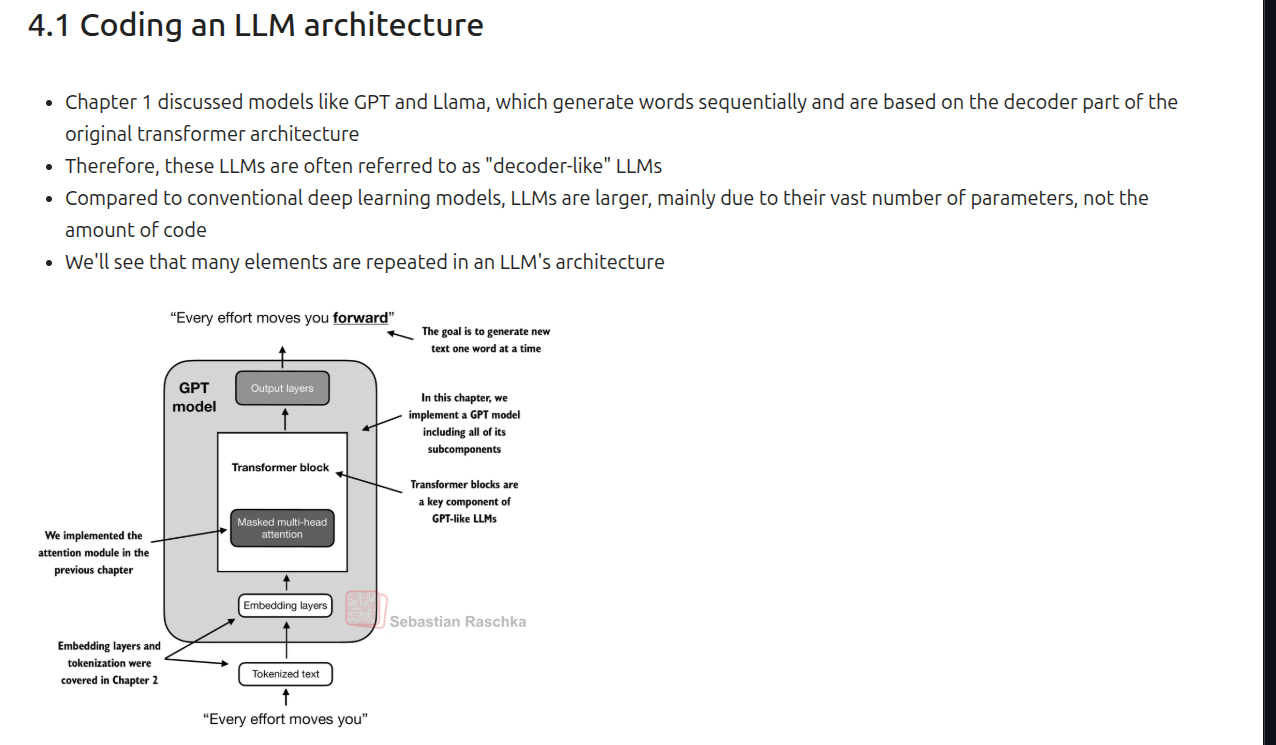

In [122]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,  # Vocabulary size - used for tokenization
    "context_length": 1024,  # Context length - maximum number of tokens in a sequence for predicting of the next token
    "emb_dim": 768,  # Embedding dimension - Dimension of the token embeddings (contextual embeddings)
    "n_heads": 12,  # Number of attention heads - 12 pairs of attention heads in the multi-head attention mechanism
    "n_layers": 12,  # Number of layers - Number of transformer blocks in the model
    "drop_rate": 0.1,  # Dropout rate
    "qkv_bias": False,  # Query-Key-Value bias
}


<div class="alert alert-block alert-warning">

For comparison, the smallest GPT-2 model (117 million parameters) has 12 attention
heads and a context vector embedding size of 768. 

The largest GPT-2 model (1.5 billion
parameters) has 25 attention heads and a context vector embedding size of 1600.

Note
that the embedding sizes of the token inputs and context embeddings are the same in GPT
models (d_in = d_out).

</div>

### GPT ARCHITECTURE PART 1 : DUMMY GPT MODEL CLASS

In [123]:
import torch
import torch.nn as nn


class DummyGPTModel(nn.Module):
    def __init__(self, config):
        super().__init__()

        # No of rows in the token embedding matrix = vocab_size (50257) , No of columns = emb_dim (768)
        # Thus token embedding matrix is kind of a look-up table for the token embeddings. We get the corresponding token embedding for a given token by looking up the row corresponding to the token's index in the embedding matrix.
        
        self.token_embeddings = nn.Embedding(config["vocab_size"], config["emb_dim"])

        # No of rows in the position embedding matrix = context_length (1024) , No of columns = emb_dim (768)
        # As we only use the current context length (1024) tokens to predict the next token, we only need to learn position embeddings for the first 1024 positions. Thus, the position embedding matrix is of size (1024, 768).

        self.position_embeddings = nn.Embedding(
            config["context_length"], config["emb_dim"]
        )

        self.drop = nn.Dropout(config["drop_rate"])

        # use a placeholder for the transformer blocks - initialize a sequence of DummyTransformerBlock instances based on the number of layers specified in the config
        self.transformer_blocks = nn.Sequential(
            *[DummyTransformerBlock(config) for _ in range(config["n_layers"])]
        )

        # The final normalization layer is a layer normalization layer that normalizes the final hidden states of the model before they are passed to the output projection layer. This helps stabilize training and improve convergence.
        self.final_normalization = DummyLayerNorm(config["emb_dim"])

        # The output projection layer is a linear layer that maps the final hidden states of the model to the vocabulary size. This is used to generate logits for each token in the vocabulary, which can then be used to predict the next token in a sequence.
        self.output_projection = nn.Linear(config["emb_dim"], config["vocab_size"], bias=False)

    def forward(self,inputs):
        # inputs: (batch_size, sequence_length) - a batch of input sequences represented as token indices
        batch_size, sequence_length = inputs.size()

        # Get the token embeddings for the input tokens
        token_embeddings = self.token_embeddings(inputs)  # (batch_size, sequence_length, emb_dim)

        positional_embeddings = self.position_embeddings(torch.arange(sequence_length, device=inputs.device))  # (sequence_length, emb_dim)

        x = token_embeddings + positional_embeddings

        x = self.drop(x)

        x = self.transformer_blocks(x)

        x = self.final_normalization(x)

        logits = self.output_projection(x)  # (batch_size, sequence_length, vocab_size)

        return logits
        


class DummyTransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        # A simple placeholder

    def forward(self, x):
        # This block does nothing and just returns its input.
        return x


class DummyLayerNorm(nn.Module):
    def __init__(self, normalized_shape, eps=1e-5):
        super().__init__()
        # The parameters here are just to mimic the LayerNorm interface.

    def forward(self, x):
        # This layer does nothing and just returns its input.
        return x


In [124]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")
batch = []
txt1 = "Every effort moves you"
txt2 = "Every day holds a"
batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)


tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


In [125]:
torch.manual_seed(123)
model = DummyGPTModel(GPT_CONFIG_124M)
logits = model.forward(batch)
print("Output shape:", logits.shape)
print(logits)


Output shape: torch.Size([2, 4, 50257])
tensor([[[-1.2034,  0.3201, -0.7130,  ..., -1.5548, -0.2390, -0.4667],
         [-0.1192,  0.4539, -0.4432,  ...,  0.2392,  1.3469,  1.2430],
         [ 0.5307,  1.6720, -0.4695,  ...,  1.1966,  0.0111,  0.5835],
         [ 0.0139,  1.6755, -0.3388,  ...,  1.1586, -0.0435, -1.0400]],

        [[-1.0908,  0.1798, -0.9484,  ..., -1.6047,  0.2439, -0.4530],
         [-0.7860,  0.5581, -0.0610,  ...,  0.4835, -0.0077,  1.6621],
         [ 0.3567,  1.2698, -0.6398,  ..., -0.0162, -0.1296,  0.3717],
         [-0.2407, -0.7349, -0.5102,  ...,  2.0057, -0.3694,  0.1814]]],
       grad_fn=<UnsafeViewBackward0>)


### GPT ARCHITECTURE PART 2 : LAYER NORMALIZATION

In [126]:
torch.manual_seed(123)
batch_example = torch.randn(2, 5)  # A
layer = nn.Sequential(nn.Linear(5, 6), nn.ReLU())
out = layer(batch_example)
print(out)


tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)


<div class="alert alert-block alert-info">

The neural network layer we have coded consists of a Linear layer followed by a non-linear
activation function, ReLU (short for Rectified Linear Unit), which is a standard activation
function in neural networks. 

If you are unfamiliar with ReLU, it simply thresholds negative
inputs to 0, ensuring that a layer outputs only positive values, which explains why the
resulting layer output does not contain any negative values.

</div>

In [127]:
mean = out.mean(dim=-1, keepdim=True)
variance = out.var(dim=-1, keepdim=True, unbiased=False)
print("Mean:", mean)
print("Variance:", variance)


Mean: tensor([[0.1324],
        [0.2170]], grad_fn=<MeanBackward1>)
Variance: tensor([[0.0192],
        [0.0332]], grad_fn=<VarBackward0>)


<div class="alert alert-block alert-warning">

Using keepdim=True in operations like mean or variance calculation ensures that the
output tensor retains the same number of dimensions as the input tensor, even though the
operation reduces the tensor along the dimension specified via dim. 

For instance, without
keepdim=True, the returned mean tensor would be a 2-dimensional vector [0.1324,
0.2170] instead of a 2×1-dimensional matrix [[0.1324], [0.2170]].
</div>

<div class="alert alert-block alert-warning">

For a 2D tensor (like a matrix), using dim = -1 for operations such as
mean or variance calculation is the same as using dim = 1. 

This is because -1 refers to the
tensor's last dimension, which corresponds to the columns in a 2D tensor. 

Later, when
adding layer normalization to the GPT model, which produces 3D tensors with shape
[batch_size, num_tokens, embedding_size], we can still use dim=-1 for normalization
across the last dimension, avoiding a change from dim=1 to dim=2.

</div>

In [128]:
normalized_output = (out - mean) / torch.sqrt(variance + 1e-5)

normalized_mean = normalized_output.mean(dim=-1, keepdim=True)
normalized_variance = normalized_output.var(dim=-1, keepdim=True, unbiased=False)

print("Normalized Output:", normalized_output)
print("Normalized Mean:", normalized_mean)
print("Normalized Variance:", normalized_variance)

# The following code sets the print options for PyTorch tensors to disable scientific notation, making it easier to read the output values. It then prints the normalized mean and variance of the normalized output.

torch.set_printoptions(sci_mode=False)
print("Mean:\n", normalized_mean)
print("Variance:\n", normalized_variance)


Normalized Output: tensor([[ 0.6745,  1.5470, -0.9549,  0.6431, -0.9549, -0.9549],
        [-0.0207,  0.1228, -1.1913,  1.6619,  0.6186, -1.1913]],
       grad_fn=<DivBackward0>)
Normalized Mean: tensor([[ 0.0000],
        [-0.0000]], grad_fn=<MeanBackward1>)
Normalized Variance: tensor([[0.9995],
        [0.9997]], grad_fn=<VarBackward0>)
Mean:
 tensor([[ 0.0000],
        [-0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[0.9995],
        [0.9997]], grad_fn=<VarBackward0>)


<div class="alert alert-block alert-success">

Let's now encapsulate this process in a PyTorch module that we can use in the GPT
model later:
</div>

In [129]:
class LayerNormalization(nn.Module):
    def __init__(self, embd_dim):
        super().__init__()
        # The variable eps is a small constant (epsilon) added to the variance to prevent division by zero during normalization.
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(embd_dim))
        self.shift = nn.Parameter(torch.zeros(embd_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        variance = x.var(dim=-1, keepdim=True, unbiased=False)
        normalized_output = (x - mean) / torch.sqrt(variance + self.eps)
        return self.scale * normalized_output + self.shift


<div class="alert alert-block alert-info">

- This specific implementation of layer Normalization operates on the last dimension of the
input tensor x, which represents the embedding dimension (emb_dim) [dim = -1]. 

- The variable eps is a
small constant (epsilon) added to the variance to prevent division by zero during
normalization. 

- The scale and shift are two trainable parameters (of the same dimension
as the input) that the LLM automatically adjusts during training if it is determined that
doing so would improve the model's performance on its training task. 

- This allows the model
to learn appropriate scaling and shifting that best suit the data it is processing.

- In our variance calculation method, we have opted for an implementation detail by setting unbiased=False.

    - In the variance calculation, we divide by the number of inputs n in the variance formula.

    - This approach does not apply Bessel's correction, which typically uses n-1 instead of n in the denominator to adjust for bias in sample variance estimation.

    - This decision results in a so-called biased estimate of the variance.

    - For large-scale language models (LLMs), where the embedding dimension n is significantly large, the difference between using n and n-1 is practically negligible.

    - We chose this approach to ensure compatibility with the GPT-2 model's normalization layers and because it reflects TensorFlow's default behavior, which was used to implement the original GPT2 model.

</div>

In [130]:
ln = LayerNormalization(embd_dim=5)
out_ln = ln(batch_example)
mean = out_ln.mean(dim=-1, keepdim=True)
var = out_ln.var(dim=-1, unbiased=False, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)


Mean:
 tensor([[-0.0000],
        [ 0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


### GPT ARCHITECTURE PART 3 : FEEDFORWARD NEURAL NETWORK WITH GELU ACTIVATION

In [131]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return (
            0.5
            * x
            * (
                1
                + torch.tanh(
                    torch.sqrt(torch.tensor(2.0 / torch.pi))
                    * (x + 0.044715 * torch.pow(x, 3))
                )
            )
        )


<div class="alert alert-block alert-success">

To get an idea of what this GELU function looks like and how it compares to the ReLU
function, let's plot these functions side by side:
</div>

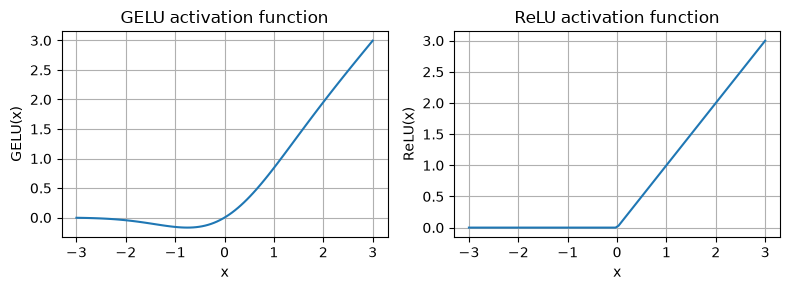

In [132]:
import matplotlib.pyplot as plt

gelu, relu = GELU(), nn.ReLU()

# Some sample data
x = torch.linspace(-3, 3, 100)
y_gelu, y_relu = gelu(x), relu(x)

plt.figure(figsize=(8, 3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)

plt.tight_layout()
plt.show()


<div class="alert alert-block alert-info">

As we can see in the resulting plot, ReLU is a piecewise linear function that
outputs the input directly if it is positive; otherwise, it outputs zero. 

GELU is a smooth, nonlinear function that approximates ReLU but with a non-zero gradient for negative values rather than zero values in ReLU fpr Negative values.

<div class="alert alert-block alert-warning">

The smoothness of GELU, as shown in the above figure, can lead to better optimization properties
during training, as it allows for more nuanced adjustments to the model's parameters. 

In contrast, ReLU has a sharp corner at zero, which can sometimes make optimization harder,
especially in networks that are very deep or have complex architectures. 

Moreover, unlike RELU, which outputs zero for any negative input, GELU allows for a small, non-zero output
for negative values. 

This characteristic means that during the training process, neurons that
receive negative input can still contribute to the learning process, albeit to a lesser extent
than positive inputs.

</div>
</div>

In [133]:
class FeedForwardLayer(nn.Module):
    def __init__(self,config):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(config["emb_dim"], 4 * config["emb_dim"]),  # First linear layer expands the embedding dimension by a factor of 4
            GELU(),  # GELU activation function
            nn.Linear(4 * config["emb_dim"], config["emb_dim"]),  # Second linear layer projects back to the original embedding dimension
        )

    def forward(self, x):
        return self.layers(x)


In [134]:
print(GPT_CONFIG_124M["emb_dim"])


768


In [135]:
feed_forward_layer = FeedForwardLayer(GPT_CONFIG_124M)

# random inputs:
x = torch.rand(2,3,768)  # (batch_size, sequence_length, emb_dim)
output = feed_forward_layer(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)


Input shape: torch.Size([2, 3, 768])
Output shape: torch.Size([2, 3, 768])


<div class="alert alert-block alert-warning">

The FeedForward module we implemented in this section plays a crucial role in enhancing
the model's ability to learn from and generalize the data. 


Although the input and output dimensions of this module are the same, it internally expands the embedding dimension
into a higher-dimensional space through the first linear layer.

This expansion is followed by a non-linear GELU activation, and then a contraction back to
the original dimension with the second linear transformation. 

Such a design allows for the
exploration of a richer representation space.

Moreover, the uniformity in input and output dimensions simplifies the architecture by enabling the stacking of multiple layers, as we will do later, without the need to adjust dimensions between them, thus making the model more scalable.

</div>

### GPT ARCHITECTURE PART 4 : SHORTCUT CONNECTIONS

<div class="alert alert-block alert-info">

Shortcut Connections also Known as "Skip" or "Residual" Connections

Initially Proposed to solve the problem of "Vanishing Gradients"

Vanishing Gradients - Gradients become progressively smaller as they propagate Backwards in a Neural network -> Making it difficult to train Layers at the Start as the Gradients tend to become zero and eventually are Ignored during the training

So Shortcut Connections solve this problem by Creatig an "Alternative Path" for the Gradients to flow , by Skipping one or more Layers

This is achieved by adding the Output of one Layer to the Output of other Layer
</div>


In [ ]:
class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut

        # The following code initializes a list of layers for the deep neural network. Each layer is defined as a sequential block consisting of a linear transformation followed by a GELU activation function. The sizes of the layers are specified in the `layer_sizes` list, which contains the number of neurons for each layer. The `nn.ModuleList` is used to store these layers, allowing for easy iteration and management of the layers in the network that is Stacking of Layers . 

        self.layers = nn.ModuleList(
            [
                nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), GELU()),
                nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), GELU()),
                nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), GELU()),
                nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), GELU()),
                nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), GELU()),
            ]
        )

    def forward(self, x):
        # The forward method defines how the input data flows through the network. It takes an input tensor `x` and passes it through each layer in the `self.layers` list. If `self.use_shortcut` is set to True, a shortcut connection is added by adding the input tensor `x` to the output of each layer. This can help with gradient flow and improve training for deep networks. The final output is returned after passing through all layers.

        for layer in self.layers:
            print("Input shape:", x.shape)

            # compute the output of the current layer
            current_layer_output = layer(x)
            print("Current layer output shape:", current_layer_output.shape)

            # if use_shortcut is True, add the input x to the output of the current layer to create a shortcut connection
            if self.use_shortcut and x.shape == current_layer_output.shape:
                print("Using shortcut connection")
                x = current_layer_output + x
                # this acts as a input to the next layer in the next iteration`zxc`
                
            # update x to be the input of the next layer for the next iteration
            else:
                x = current_layer_output
        return current_layer_output


In [137]:
layer_sizes = [3,3,3,3,3,1]
sample_input = torch.tensor([[1.0, 0.0, -1.0]])
torch.manual_seed(123)
model_without_shortcut = ExampleDeepNeuralNetwork(layer_sizes, use_shortcut=False)



In [138]:
def print_shapes(model, input_tensor):
    print("Input shape:", input_tensor.shape)
    output = model(input_tensor)
    print("Output shape:", output.shape)

def print_gradients(model,x):
    # Forward pass through the model to get the output
    output = model(x)
    target = torch.tensor([[0.]])

    loss = nn.MSELoss()(output, target)

    # Backward pass to compute gradients
    loss.backward()

    for name, param in model.named_parameters():
        if "weight" in name:
            # print the mean absolute value of the gradients for each weight parameter in the model
            print(f"Gradients for {name}: {param.grad.abs().mean().item()}")


In [139]:
print_gradients(model_without_shortcut, sample_input)


Input shape: torch.Size([1, 3])
Current layer output shape: torch.Size([1, 3])
Input shape: torch.Size([1, 3])
Current layer output shape: torch.Size([1, 3])
Input shape: torch.Size([1, 3])
Current layer output shape: torch.Size([1, 3])
Input shape: torch.Size([1, 3])
Current layer output shape: torch.Size([1, 3])
Input shape: torch.Size([1, 3])
Current layer output shape: torch.Size([1, 1])
Gradients for layers.0.0.weight: 0.00020173584925942123
Gradients for layers.1.0.weight: 0.00012011159560643137
Gradients for layers.2.0.weight: 0.0007152040489017963
Gradients for layers.3.0.weight: 0.0013988736318424344
Gradients for layers.4.0.weight: 0.005049645435065031


In [140]:
torch.manual_seed(123)
model_with_shortcut = ExampleDeepNeuralNetwork(layer_sizes, use_shortcut=True)
# print_shapes(model_with_shortcut, sample_input)
print_gradients(model_with_shortcut, sample_input)


Input shape: torch.Size([1, 3])
Current layer output shape: torch.Size([1, 3])
Using shortcut connection
Input shape: torch.Size([1, 3])
Current layer output shape: torch.Size([1, 3])
Using shortcut connection
Input shape: torch.Size([1, 3])
Current layer output shape: torch.Size([1, 3])
Using shortcut connection
Input shape: torch.Size([1, 3])
Current layer output shape: torch.Size([1, 3])
Using shortcut connection
Input shape: torch.Size([1, 3])
Current layer output shape: torch.Size([1, 1])
Gradients for layers.0.0.weight: 0.22169791162014008
Gradients for layers.1.0.weight: 0.20694105327129364
Gradients for layers.2.0.weight: 0.32896995544433594
Gradients for layers.3.0.weight: 0.2665732204914093
Gradients for layers.4.0.weight: 1.3258540630340576


<div class="alert alert-block alert-info">
As we can see, based on the output, the last layer (layers.4) still has a larger gradient
than the other layers. 

However, the gradient value stabilizes as we progress towards the
first layer (layers.0) and doesn't shrink to a vanishingly small value.
</div>

<div class="alert alert-block alert-warning">

In the preceding code, we specify a loss function that computes how close the model output
and a user-specified target (here, for simplicity, the value 0) are. 

Then, when calling loss.backward(), PyTorch computes the loss gradient for each layer in the model. 

We can iterate through the weight parameters via model.named_parameters(). 

Suppose we have a 3×3 weight parameter matrix for a given layer. 

In that case, this layer will have 3×3 gradient values, and we print the mean absolute gradient of these 3×3 gradient values to
obtain a single gradient value per layer to compare the gradients between layers more
easily.

In short, the .backward() method is a convenient method in PyTorch that computes loss
gradients, which are required during model training, without implementing the math for the
gradient calculation ourselves, thereby making working with deep neural networks much
more accessible. 

</div>